# Notebook to setup the radcalnet_oc package

In [2]:

import os, shutil
import glob

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]

plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
import numpy as np
import xarray as xr
import pandas as pd

import radcalnet_oc as radoc

print(f'-radcalnet_oc: {radoc.__version__}')


-radcalnet_oc: 0.0.1


### full spectral resolution

In [3]:
central_wl = np.arange(350, 2500, .1)

lut= radoc.LUT(wl=central_wl)
lut.load_auxiliary_data()


INFO:root:loading look-up tables
INFO:root:loading look-up tables


In [30]:

fwhm=3

szas=[30,45,60]
vza=0
lut.lut_preparation(sza=szas,vza=[vza],aerosol_combination=[0, 0., 0, 1., 0.,1])
szas = lut.Rdiff_lut.sza
mu0 = np.cos(np.radians(szas))
# tcwv cm into kg.m-2
tpw_cm=2.6
tcwv=tpw_cm*10 

to3_du=300 
pressure=1000

# conversion O3 du to kg.m-2
tco3=to3_du *6.4286e-3/300
tcno2=3e-6/100
tcch4= 1e-2

# set total transmittance values
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.air_mass=1./np.cos(np.radians(szas))+1./np.cos(np.radians(vza))

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()


# get solar irradiance
solar_irr=radoc.SolarIrradiance()
signal = solar_irr.tsis
F0 = signal*mu0
# signal convolution on spectral responses
signal=Ttot
wl_signal = signal.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = signal.interp(wl=F0.wl.values)
# get top-of-atmosphere reflectance or radiance
Rtoa=Tg*lut.Rdiff_lut.squeeze().interp(wl=F0.wl.values)
Ltoa=Rtoa*F0/np.pi


INFO:root:LUT preparation


In [31]:
Ltoa

<xarray.DataArray (sza: 3, wl: 92001, aot_ref: 25)> Size: 55MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]])
Coordinates:
    wind     float64 8B 2.0
  * sza      (sza) int64 24B 30 45 60
  * wl       (wl) float64 736kB 300.0 300.0 300.1 ... 2.6e+03 2.6e+03 2.6e+03
    vza      int64 8B 0
    azi      int64 8B 0
  * aot_ref  (aot_ref) float64 200B 0.0 0.03333 0.06667 ... 0.7333 0.7667 0.8

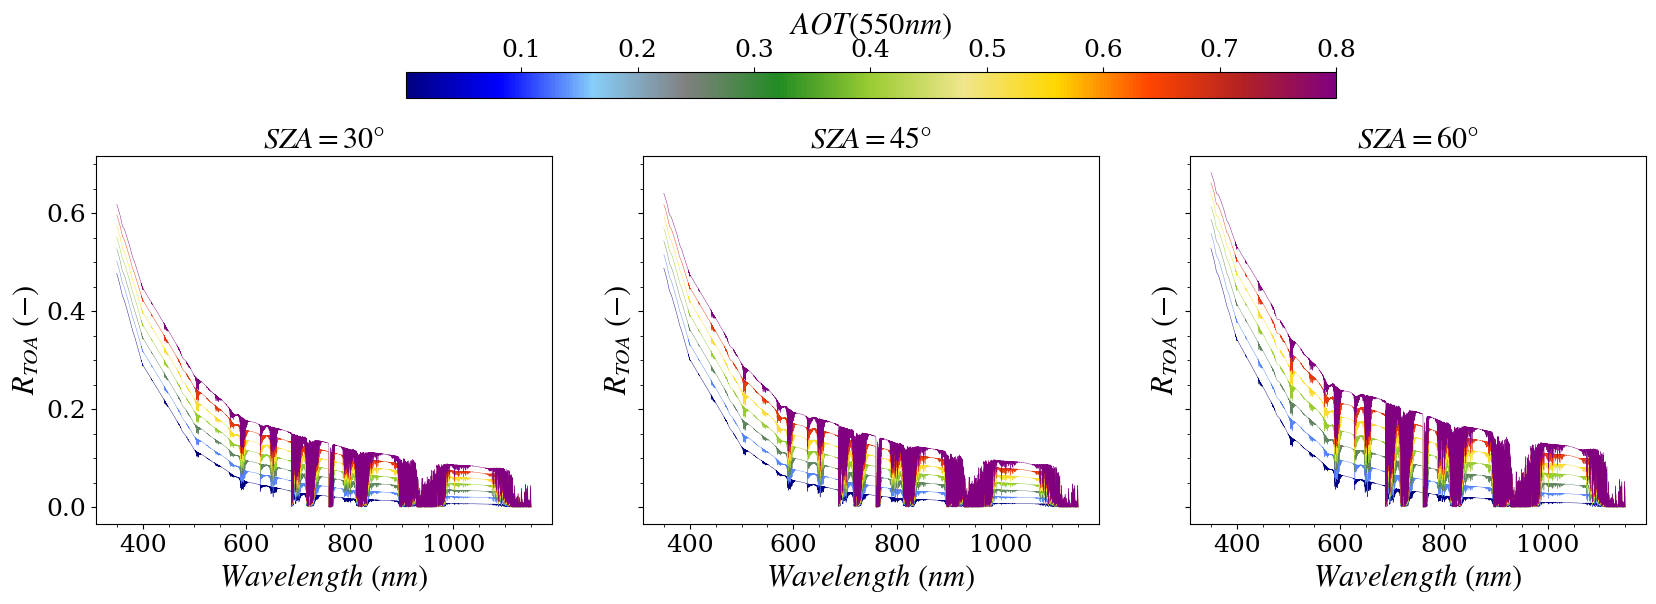

In [32]:

wl_range=slice(350,1150)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::4]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=0.3,ax=ax)
      
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [33]:
Rtoa_

<xarray.DataArray (wl: 32001)> Size: 256kB
array([6.83058562e-01, 6.83003476e-01, 6.82948385e-01, ...,
       6.67966980e-11, 9.37023221e-11, 1.20606766e-10])
Coordinates:
    wind     float64 8B 2.0
    sza      int64 8B 60
  * wl       (wl) float64 256kB 350.0 350.0 350.1 ... 1.15e+03 1.15e+03 1.15e+03
    vza      int64 8B 0
    azi      int64 8B 0
    aot_ref  float64 8B 0.8

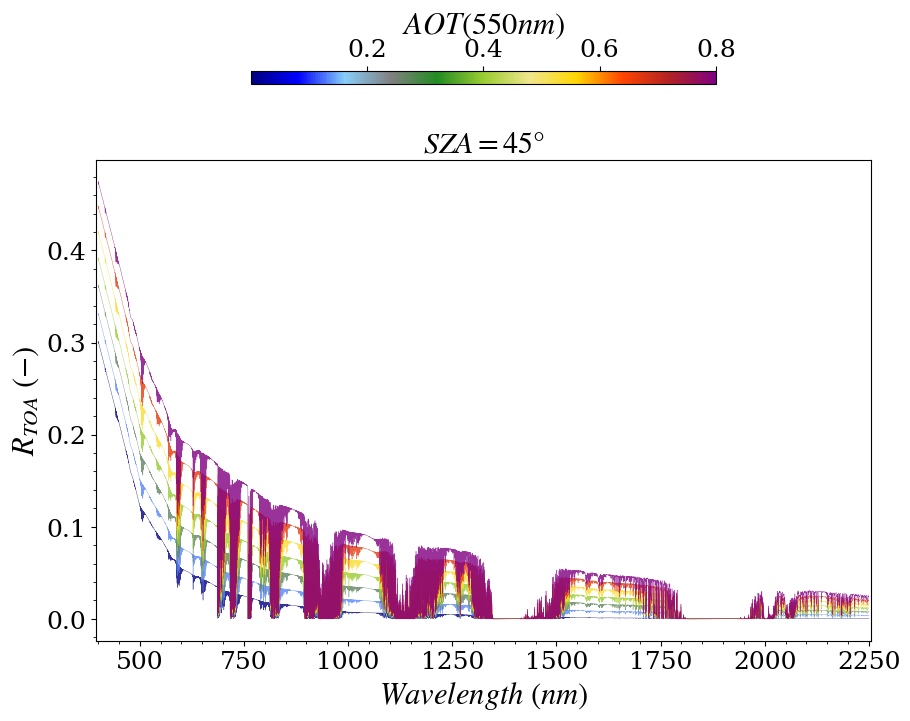

In [42]:

wl_range=slice(400,2250)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,1,figsize=(10,8.5),sharey=True)
ax=axs

sza=45
   
for aot_ref in Rtoa.aot_ref.values[::4]:
    Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
    #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
    Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=0.3,alpha=0.8,ax=axs)
  
ax.set_title(r'$SZA='+str(sza)+r'\degree$')
ax.set_ylabel(r'$R_{TOA}\ (-)$')
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.minorticks_on()
ax.set_xlim(395,2255)
cb = fig.colorbar(sm, ax=axs, shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

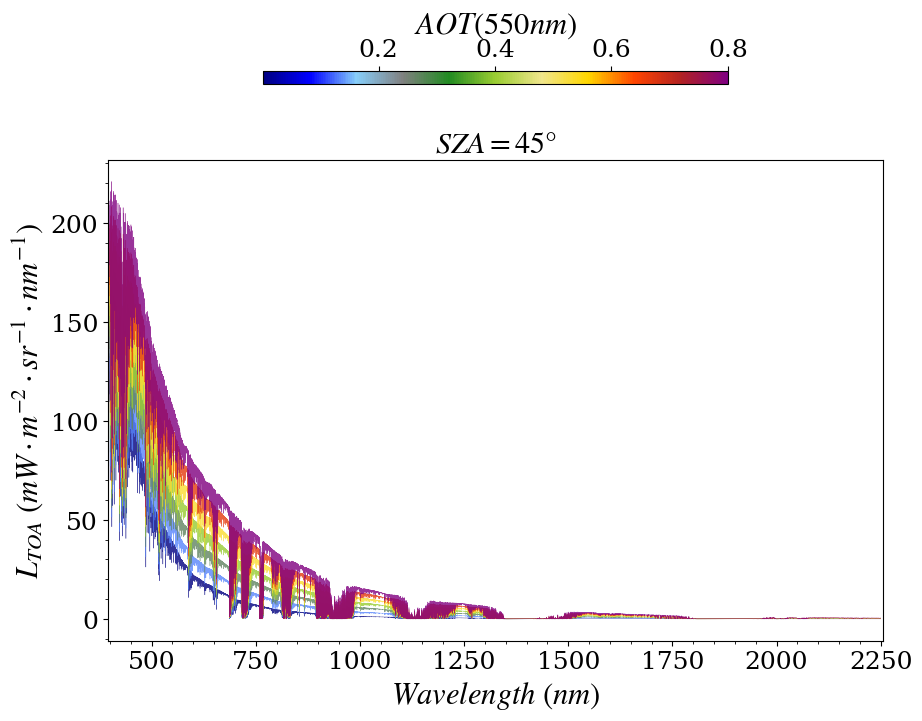

In [44]:

wl_range=slice(400,2250)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,1,figsize=(10,8.5),sharey=True)
ax=axs

sza=45
   
for aot_ref in Rtoa.aot_ref.values[::4]:
    Rtoa_=Ltoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
    #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
    Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=0.3,alpha=0.8,ax=axs)
  
ax.set_title(r'$SZA='+str(sza)+r'\degree$')
ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.minorticks_on()
ax.set_xlim(395,2255)
cb = fig.colorbar(sm, ax=axs, shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

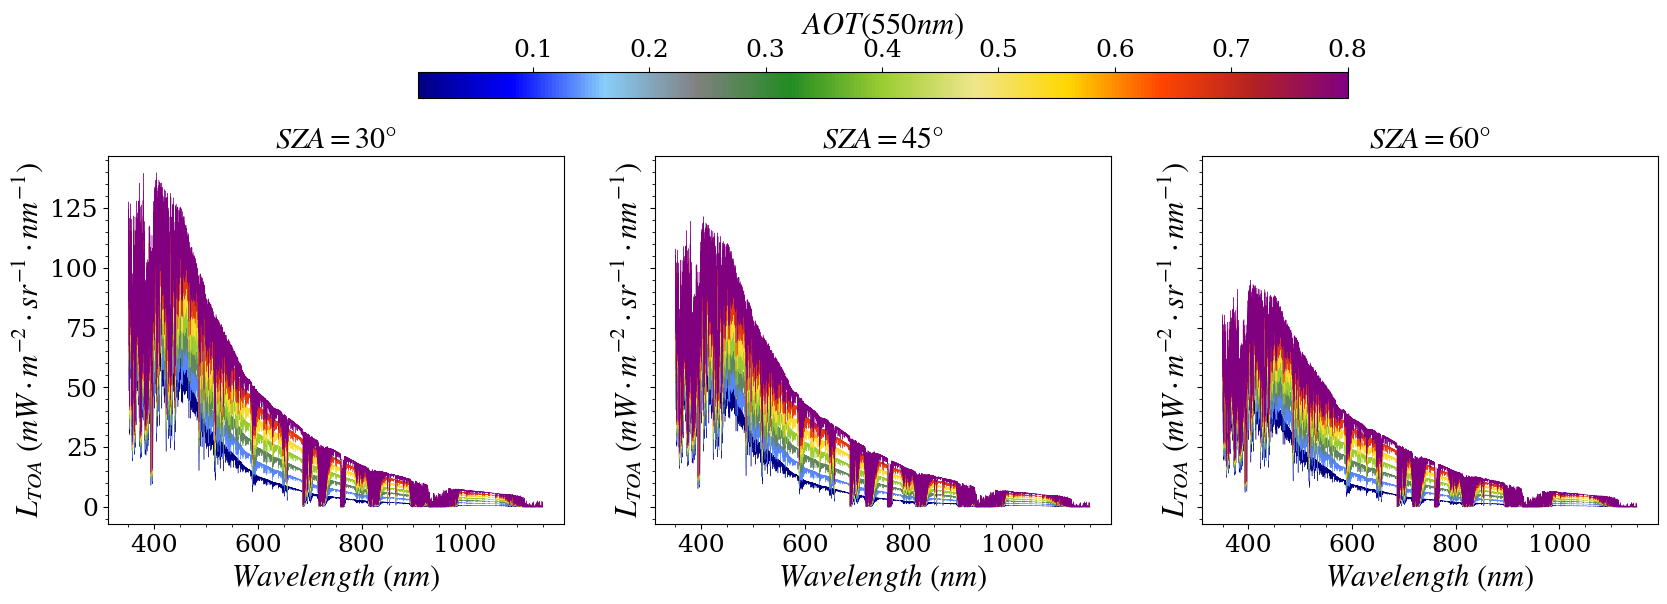

In [22]:



cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::4]:
        Ltoa_=Ltoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Ltoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=0.3,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

### with spectral convolution

In [4]:
central_wl = np.arange(350, 2500, 1)

lut= radoc.LUT(wl=central_wl)
lut.load_auxiliary_data()


In [5]:

fwhm=3

szas=[30,45,60]
vza=0
lut.lut_preparation(sza=szas,vza=[vza],weights=[0, 0., 0, 0., 0.,1])
szas = lut.Rdiff_lut.sza
mu0 = np.cos(np.radians(szas))
# tcwv cm into kg.m-2
tpw_cm=2.6
tcwv=tpw_cm*10 

to3_du=300 
pressure=1000

# conversion O3 du to kg.m-2
tco3=to3_du *6.4286e-3/300
tcno2=3e-6/100
tcch4= 1e-2

# set total transmittance values
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)
gas_trans.pressure=pressure
gas_trans.gas_tc['h2o'] = tcwv
gas_trans.gas_tc['o3'] = tco3
gas_trans.gas_tc['ch4'] = tcch4
gas_trans.air_mass=1./np.cos(np.radians(szas))+1./np.cos(np.radians(vza))

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

# signal convolution on spectral responses
signal=Ttot
wl_signal = signal.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal,name='Ttot')

# get solar irradiance
solar_irr=radoc.SolarIrradiance()
signal = solar_irr.tsis
F0 = spectral.convolve(signal)*mu0

# get top-of-atmosphere reflectance or radiance
Rtoa=Tg*lut.Rdiff_lut.squeeze()
Ltoa=Rtoa*F0/np.pi


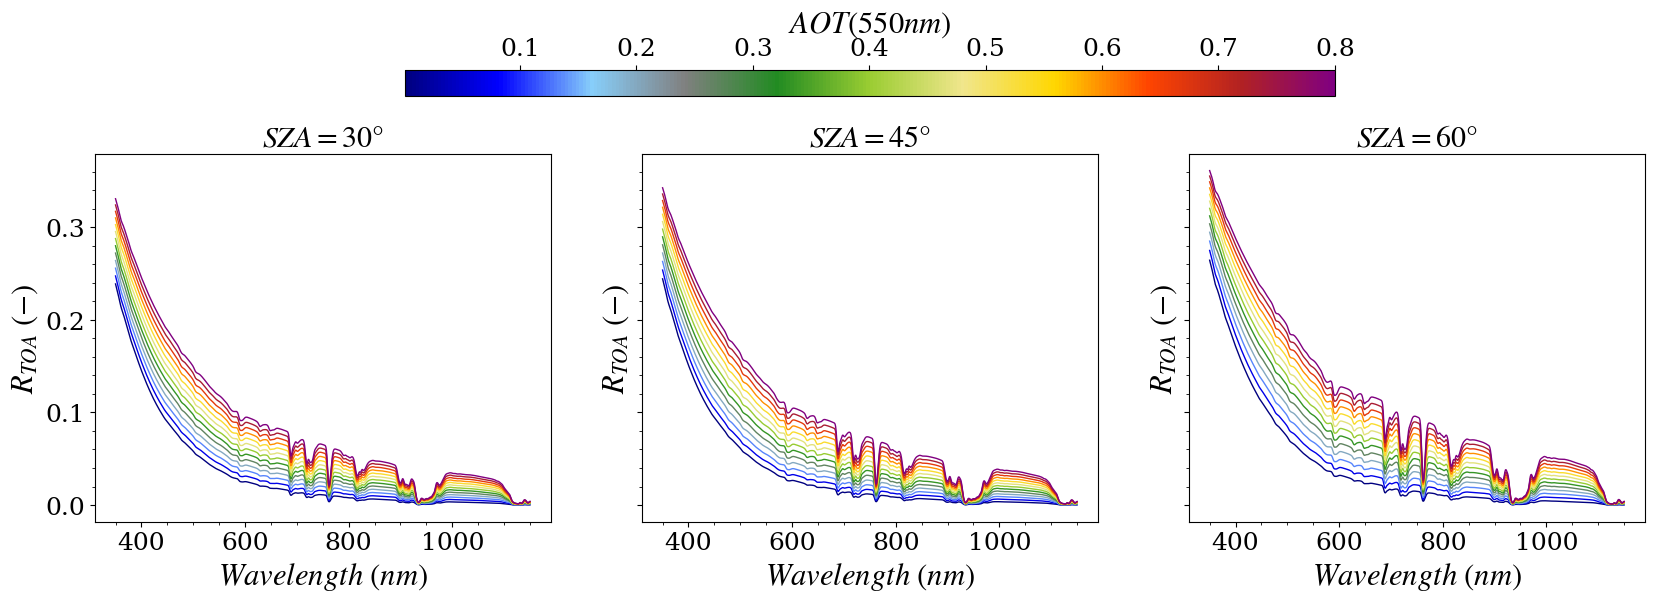

In [6]:

wl_range=slice(350,1150)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
      
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

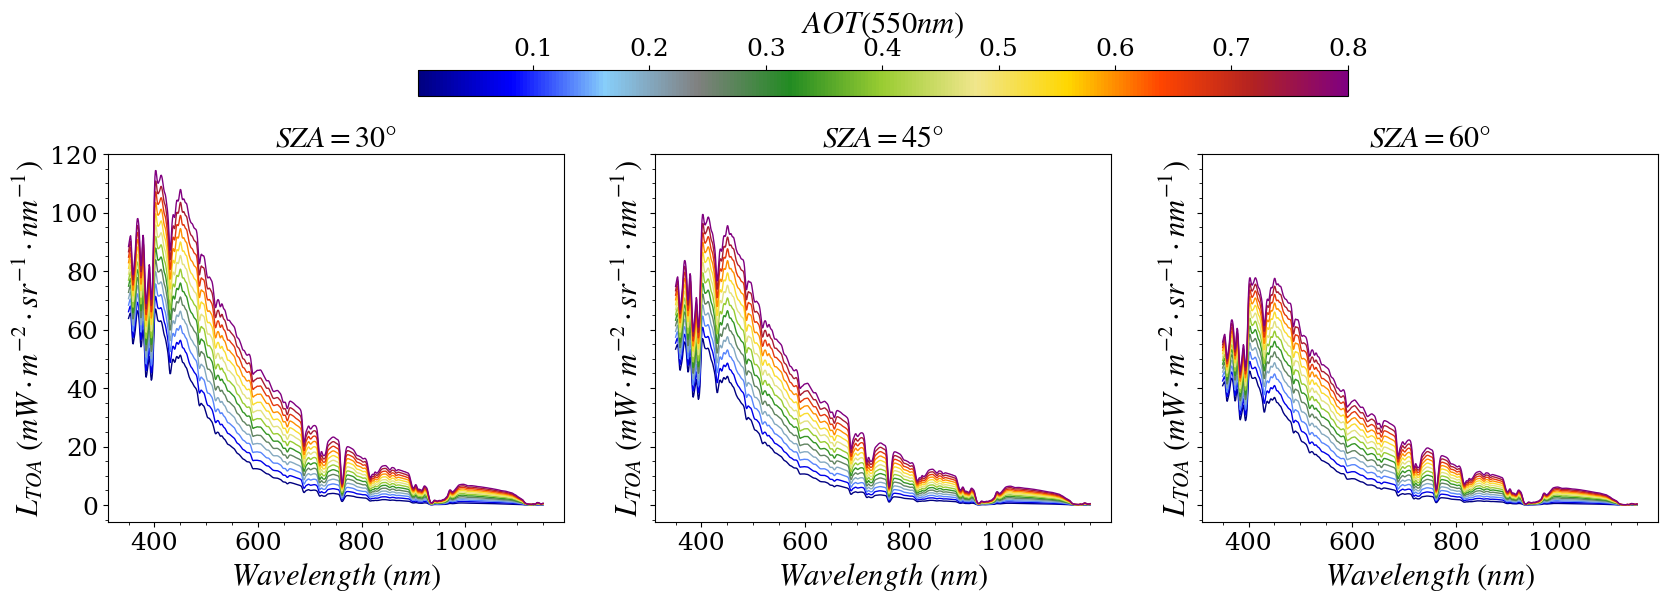

In [7]:



cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])

norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

sm.set_array([])
fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Ltoa_=Ltoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Ltoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$L_{TOA}\ (mW\cdot m^{-2}\cdot sr^{-1}\cdot nm^{-1})$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

In [6]:
## Check sensitivity to aerosol model

In [7]:
Rtoa_

<xarray.DataArray (variable: 1, wl: 801)> Size: 6kB
array([[0.36100603, 0.35938242, 0.35773295, 0.35602338, 0.35421026,
        0.35224223, 0.35007022, 0.34768892, 0.34519176, 0.34278086,
        0.34070298, 0.33913309, 0.33806995, 0.3373278 , 0.33664548,
        0.33582474, 0.33479127, 0.33356492, 0.33220282, 0.33076   ,
        0.32927371, 0.32776672, 0.32625379, 0.32473372, 0.32317725,
        0.32153873, 0.31978534, 0.31791945, 0.31599674, 0.31414052,
        0.31250857, 0.31119787, 0.31016784, 0.30926785, 0.30834057,
        0.30729997, 0.30613495, 0.30487366, 0.30355473, 0.30221327,
        0.30087457, 0.29955376, 0.2982554 , 0.29696964, 0.29567552,
        0.29435735, 0.29301798, 0.29167562, 0.29035379, 0.2890737 ,
        0.28784787, 0.2866711 , 0.28551628, 0.28434981, 0.28315854,
        0.2819527 , 0.28073926, 0.27950951, 0.27826229, 0.2770216 ,
        0.27581484, 0.27464417, 0.27349385, 0.27235947, 0.27125143,
        0.27016812, 0.26908534, 0.26798029, 0.26685264, 0.26571792,
        0.26459025, 0.26347561, 0.26237677, 0.26130084, 0.26025722,
        0.25924366, 0.25824074, 0.25723088, 0.25621527, 0.25520229,
        0.25419238, 0.25318165, 0.25216513, 0.25113829, 0.25011152,
        0.24911232, 0.24815308, 0.24720662, 0.24623272, 0.24521745,
        0.24416383, 0.24306429, 0.24192034, 0.24077529, 0.23969338,
        0.23871563, 0.23785009, 0.23708647, 0.23640475, 0.23576959,
...
        0.04602085, 0.04582208, 0.04562535, 0.04543215, 0.0452426 ,
        0.04505383, 0.04486244, 0.04467043, 0.0444859 , 0.0443157 ,
        0.04415687, 0.04399541, 0.04381839, 0.04363087, 0.04345403,
        0.04329966, 0.04315121, 0.04298002, 0.04277921, 0.04257206,
        0.04237677, 0.04217394, 0.04193719, 0.04166039, 0.04133633,
        0.04098786, 0.04067952, 0.04039484, 0.04000074, 0.03942247,
        0.03877999, 0.03830396, 0.03808157, 0.0379181 , 0.03758397,
        0.03708015, 0.03647651, 0.0357189 , 0.03478389, 0.03380249,
        0.03290972, 0.0320363 , 0.03089484, 0.02930377, 0.02748771,
        0.02584224, 0.02451246, 0.02340324, 0.0224013 , 0.02140544,
        0.02033268, 0.0191934 , 0.01806501, 0.01704361, 0.01617845,
        0.01529287, 0.01402007, 0.01217517, 0.00996219, 0.00776351,
        0.00586756, 0.00443382, 0.00350324, 0.00293631, 0.00251117,
        0.00212404, 0.00180563, 0.00160431, 0.00150669, 0.00142959,
        0.00129835, 0.00113393, 0.00103722, 0.00113035, 0.00149654,
        0.00204515, 0.00244272, 0.00237194, 0.00191362, 0.00153952,
        0.00170958, 0.0025437 , 0.00380271, 0.00504791, 0.00584932,
        0.00602056, 0.00571114, 0.00515856, 0.00441472, 0.00349592,
        0.00266998, 0.00232925, 0.00258733, 0.00315086, 0.00364173,
        0.00395609]])
Coordinates:
  * wl        (wl) int64 6kB 350 351 352 353 354 ... 1146 1147 1148 1149 1150
    sza       int64 8B 60
  * variable  (variable) object 8B 'Ttot'
    wind      float64 8B 2.0
    vza       int64 8B 0
    azi       int64 8B 0
    aot_ref   float64 8B 0.8

In [12]:
Tg.squeeze()

<xarray.DataArray 'Ttot' (wl: 2150)> Size: 9kB
array([0.9957693 , 0.99583   , 0.9958183 , ..., 0.00238362, 0.00460068,
       0.00746545], dtype=float32)
Coordinates:
  * wl       (wl) int64 17kB 350 351 352 353 354 ... 2495 2496 2497 2498 2499

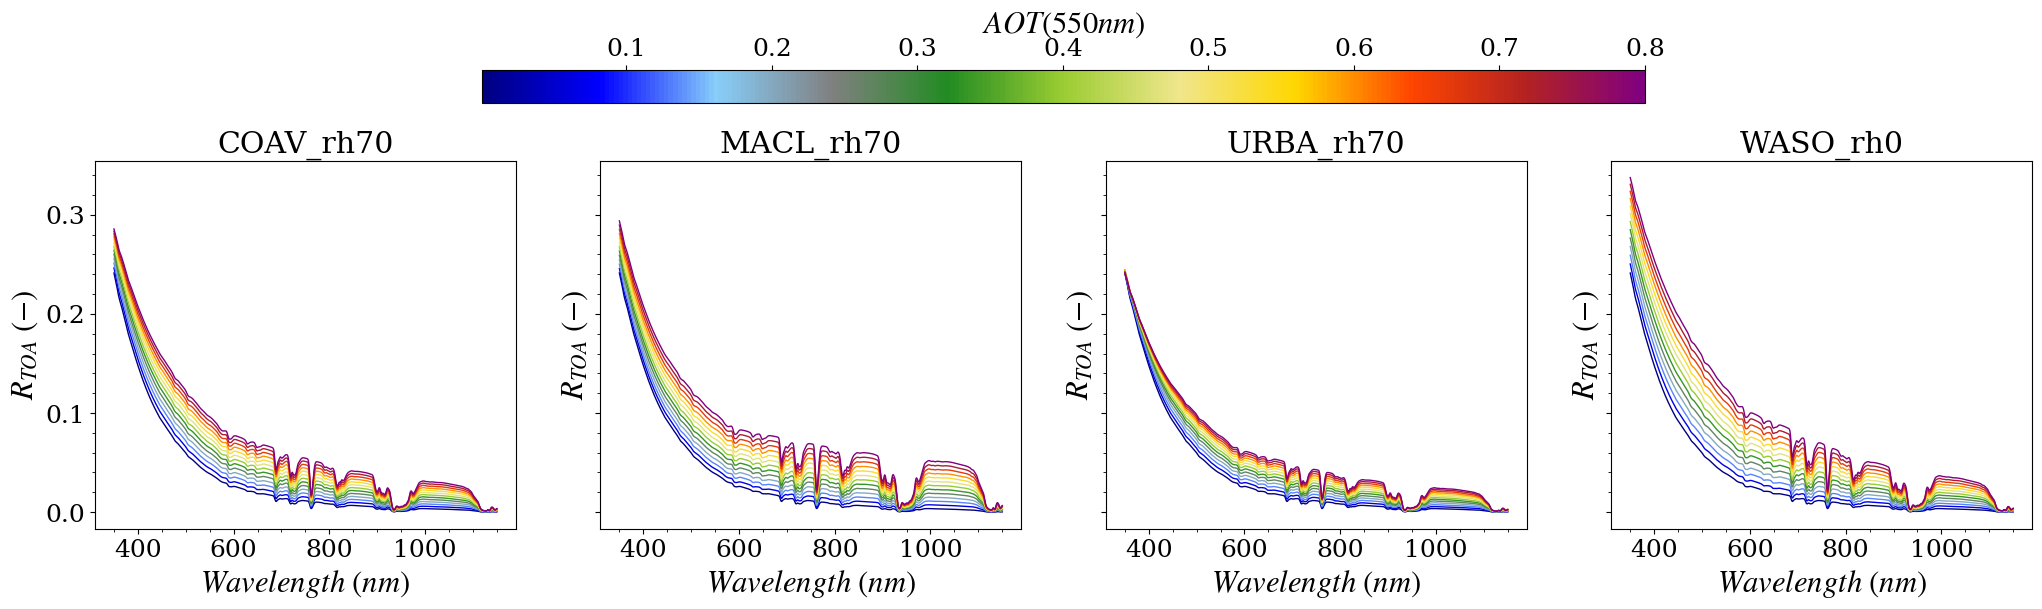

In [9]:
wl_range=slice(350,1150)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

lut= radoc.LUT(wl=central_wl)

szas=[40]

models= ['ARCT_rh70', 'COAV_rh70', 'DESE_rh70', 'MACL_rh70', 'URBA_rh70','WASO_rh0']

gas_trans.air_mass=1./np.cos(np.radians(szas))+1./np.cos(np.radians(vza))

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

# signal convolution on spectral responses
signal=Ttot
wl_signal = signal.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal,name='Ttot')

# get solar irradiance
solar_irr=radoc.SolarIrradiance()
signal = solar_irr.tsis
F0 = spectral.convolve(signal)*mu0

fig,axs = plt.subplots(1,4,figsize=(25,6.5),sharey=True)
axs=axs.ravel()

for ii, weights in enumerate([[0, 1., 0, 0., 0.,0],[0, 0., 0, 1., 0.,0],[0, 0., 0, 0., 1.,0],[0, 0., 0, 0., 0.,1]]):
    ax=axs[ii]
    imodel=np.argmax(weights)
    lut.lut_preparation(wind=2,
                        sza=szas,
                        vza=[0],
                        azi=[0],
                        aot_refs=np.linspace(0.0, 0.8, 25),
                        weights=weights)
    
    
    Rtoa=Tg*lut.Rdiff_lut.squeeze()
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
      
    ax.set_title(models[imodel])
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
#ax.set_ylim(0,0.36)
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)


## Check wind speed impact

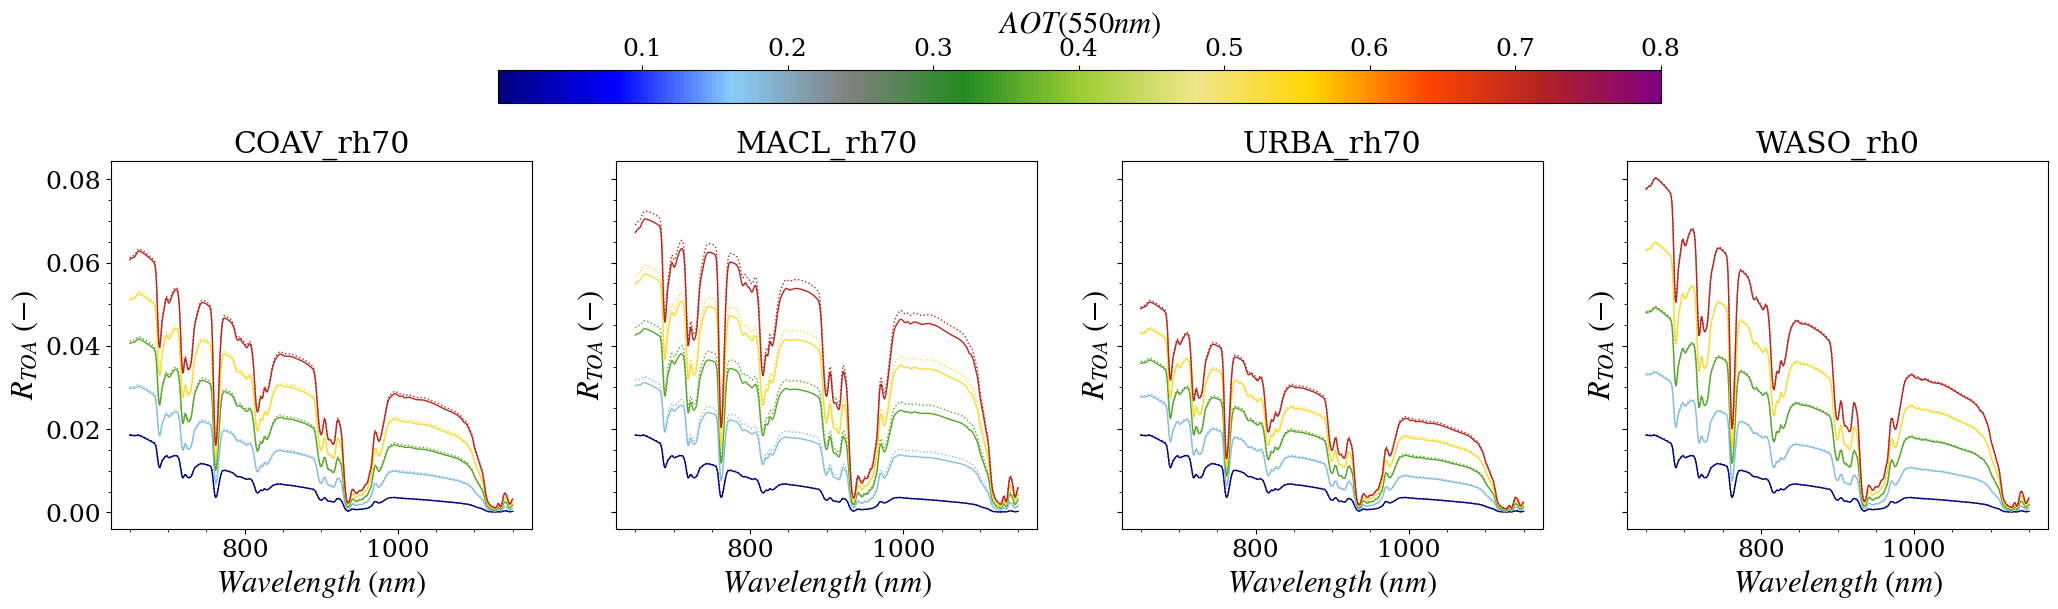

In [16]:
wl_range=slice(650,1150)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

lut= radoc.LUT(wl=central_wl)

szas=[40]

models= ['ARCT_rh70', 'COAV_rh70', 'DESE_rh70', 'MACL_rh70', 'URBA_rh70','WASO_rh0']

gas_trans.air_mass=1./np.cos(np.radians(szas))+1./np.cos(np.radians(vza))

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

# signal convolution on spectral responses
signal=Ttot
wl_signal = signal.wl.values
spectral=radoc.Spectral(central_wl,fwhm)
Tg = spectral.convolve(signal,name='Ttot')

# get solar irradiance
solar_irr=radoc.SolarIrradiance()
signal = solar_irr.tsis
F0 = spectral.convolve(signal)*mu0

fig,axs = plt.subplots(1,4,figsize=(25,6.5),sharey=True)
axs=axs.ravel()

for ii, weights in enumerate([[0, 1., 0, 0., 0.,0],[0, 0., 0, 1., 0.,0],[0, 0., 0, 0., 1.,0],[0, 0., 0, 0., 0.,1]]):
    ax=axs[ii]
    imodel=np.argmax(weights)
    lut.lut_preparation(wind=2,
                        sza=szas,
                        vza=[0],
                        azi=[0],
                        aot_refs=np.linspace(0.0, 0.8, 10),
                        weights=weights)
    
    
    Rtoa=Tg*lut.Rdiff_lut.squeeze()
    lut.lut_preparation(wind=8,
                        sza=szas,
                        vza=[0],
                        azi=[0],
                        aot_refs=np.linspace(0.0, 0.8, 10),
                        weights=weights)
    
    
    Rtoa2=Tg*lut.Rdiff_lut.squeeze()
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
        Rtoa_=Rtoa2.sel(aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=ax)
    ax.set_title(models[imodel])
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()
#ax.set_ylim(0,0.36)
cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)


In [10]:
lut= radoc.LUT(wl=central_wl)
lut.lut_preparation(wind=2,
                    sza=szas,
                    vza=[0],
                    azi=[0],
                    aot_refs=np.linspace(0.0, 0.8, 25),
                    weights=[0, 0.5, 1, 0., 0.])
lut2= radoc.LUT(wl=central_wl)
lut2.lut_preparation(wind=6,
                    sza=szas,
                    vza=[0],
                    azi=[0],
                    aot_refs=np.linspace(0.0, 0.8, 25),
                    weights=[0, 0.5, 1, 0., 0.])



In [ ]:
Rtoa=Tg*lut.Rdiff_lut.squeeze()
Rtoa2=Tg*lut2.Rdiff_lut.squeeze()

TypeError: iteration over a 0-d array

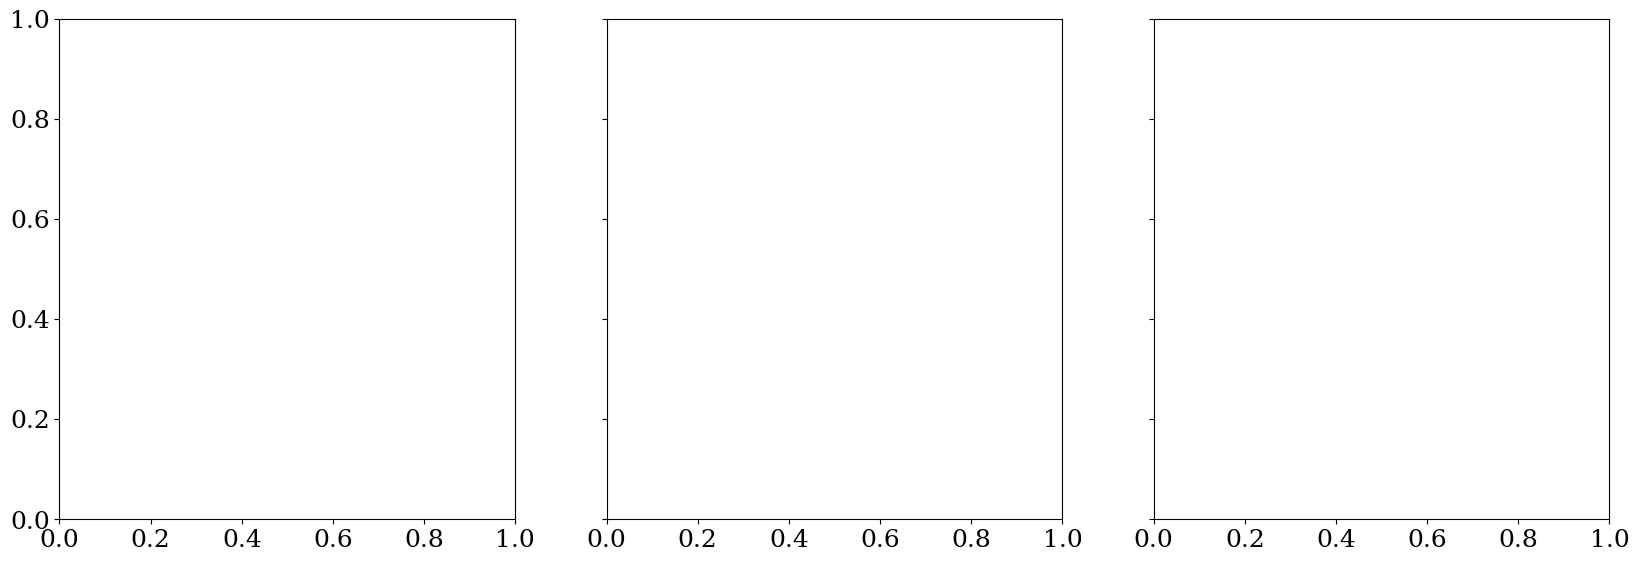

In [ ]:
wl_range=slice(1250,1780)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
        Rtoa_=Rtoa2.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
       
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

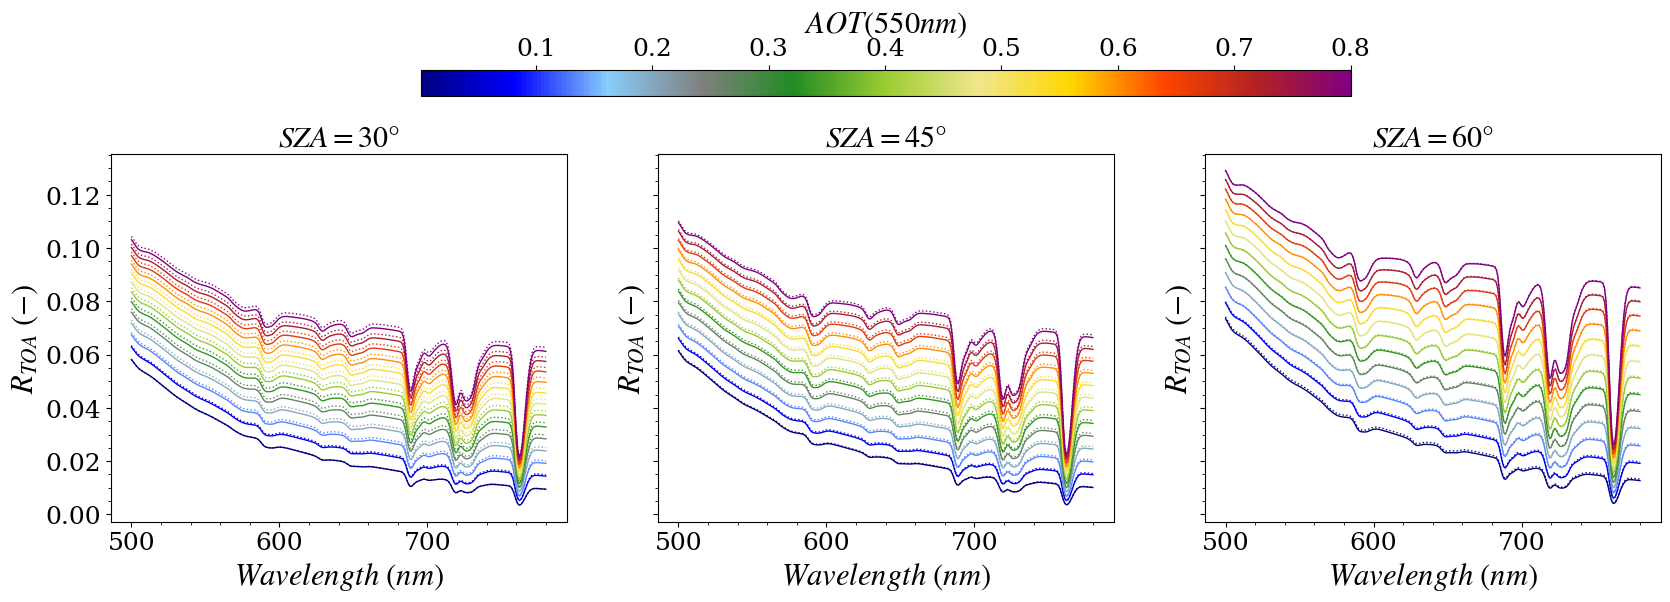

In [15]:


Rtoa=Tg*lut.Rdiff_lut.squeeze()
Rtoa2=Tg*lut2.Rdiff_lut.squeeze()
wl_range=slice(500,780)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig,axs = plt.subplots(1,3,figsize=(20,6.5),sharey=True)
axs=axs.ravel()

for isza, sza in enumerate(Rtoa.sza.values):
    ax=axs[isza]
    for aot_ref in Rtoa.aot_ref.values[::2]:
        Rtoa_=Rtoa.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
        #Rsim.sel(aot_ref=aot_ref).plot(x='wl',color=cmap(norm(aot_ref)),add_legend=False,ls=':',lw=1,ax=axs[i_])
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),lw=1,ax=ax)
        Rtoa_=Rtoa2.sel(sza=sza,aot_ref=aot_ref).sel(wl=wl_range) #+ Tabs*Ttot*  np.pi * Rrs
       
        Rtoa_.plot(x='wl',color=cmap(norm(aot_ref)),ls=':',lw=1,ax=ax)
    ax.set_title(r'$SZA='+str(sza)+r'\degree$')
    ax.set_ylabel(r'$R_{TOA}\ (-)$')
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.minorticks_on()

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)